# **Jena Weather Time Series**

# **Nama : Doni Firmansyah**

In [ ]:
# @markdown Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

In [ ]:
# @markdown Collecting Data :\
# @markdown Dataset yang digunakan adalah dari https://www.kaggle.com/datasets/mnassrib/jena-weather-dataset

# unzip file
!unzip jena_weather_2004_2020.zip
# baca file csv menjadi dataframe
df = pd.read_csv('jena_weather_2004_2020.csv')
# ambil data tanggal dan temp sebanyak 200254 baris
df = df[["Date Time","T (degC)"]][-200254::]
# rename columns
df.rename(columns={"Date Time":"datetime","T (degC)":"temp"},inplace=True)

Archive:  jena_weather_2004_2020.zip
  inflating: jena_weather_2004_2020.csv  


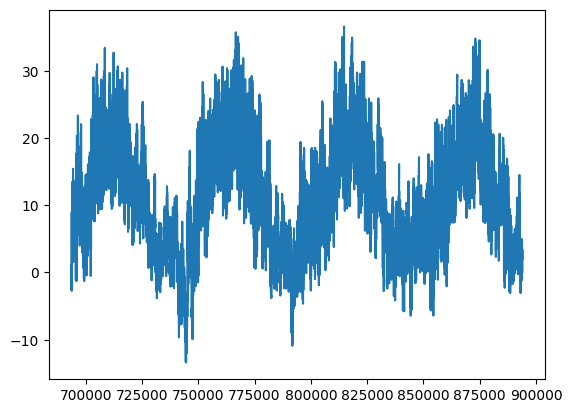

In [ ]:
# @markdown Visualizing Data

# cek dataset temp
plt.plot(df["temp"])
plt.show()

In [ ]:
# @markdown Cleaning Data

print(f"Jumlah Data\n{df.count()}\n")

# cek duplikat
print(f"Jumlah Data Duplikat {df.duplicated().sum()}\n")
df.drop_duplicates(inplace=True)

# cek data kosong
print(f"Jumlah Data Kosong\n{df.isnull().sum()}\n")
df.dropna(inplace=True)

print(f"Jumlah Setelah Dibersihkan\n{df.count()}\n")

Jumlah Data
datetime    200254
temp        200254
dtype: int64

Jumlah Data Duplikat 1

Jumlah Data Kosong
datetime    0
temp        0
dtype: int64

Jumlah Setelah Dibersihkan
datetime    200253
temp        200253
dtype: int64



In [ ]:
# @markdown Pre-Processing Data :\
# @markdown Normalization

# membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]
dataTemp = tf.expand_dims(df['temp'].values, axis=-1)
print("membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]")
print(dataTemp[0:144])
print("-----------------------------------------------------------\n")

# Normalization
scaler = MinMaxScaler()
scaledDataTemp = scaler.fit_transform(dataTemp)
print("Scaled")
print(scaledDataTemp[0:144])
print("-----------------------------------------------------------\n")

membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]
tf.Tensor(
[[ 1.12]
 [ 1.1 ]
 [ 1.07]
 [ 1.09]
 [ 1.03]
 [ 0.96]
 [ 0.74]
 [ 0.5 ]
 [ 0.56]
 [ 0.37]
 [ 0.49]
 [ 0.33]
 [ 0.11]
 [-0.34]
 [-0.4 ]
 [-0.67]
 [-0.97]
 [-1.18]
 [-1.34]
 [-1.34]
 [-1.44]
 [-1.53]
 [-1.89]
 [-1.85]
 [-1.86]
 [-2.03]
 [-2.03]
 [-2.06]
 [-2.07]
 [-1.98]
 [-1.95]
 [-1.93]
 [-2.17]
 [-2.42]
 [-2.49]
 [-2.45]
 [-2.55]
 [-2.65]
 [-2.46]
 [-2.16]
 [-2.28]
 [-2.33]
 [-2.48]
 [-2.51]
 [-2.44]
 [-2.3 ]
 [-2.37]
 [-2.33]
 [-2.28]
 [-2.29]
 [-2.17]
 [-1.94]
 [-1.62]
 [-1.53]
 [-1.48]
 [-1.29]
 [-0.91]
 [-0.22]
 [ 0.42]
 [ 1.08]
 [ 1.8 ]
 [ 2.65]
 [ 2.76]
 [ 3.67]
 [ 4.28]
 [ 5.26]
 [ 5.36]
 [ 6.2 ]
 [ 6.26]
 [ 6.24]
 [ 6.82]
 [ 6.82]
 [ 7.02]
 [ 7.21]
 [ 7.11]
 [ 7.46]
 [ 7.54]
 [ 7.29]
 [ 7.81]
 [ 7.92]
 [ 8.03]
 [ 7.96]
 [ 8.  ]
 [ 7.99]
 [ 8.07]
 [ 7.93]
 [ 7.97]
 [ 8.09]
 [ 8.24]
 [ 8.36]
 [ 8.29]
 [ 8.44]
 [ 8.99]
 [ 8.52]
 [ 8.12]
 [ 7.68]
 [ 7.57]
 [ 7.52]
 [ 7.48]
 [ 7.38]
 [ 7.42]
 [ 7.48]
 [ 7.45]
 [

In [ ]:
# @markdown Pre-Processing Data:\
# @markdown Split Data

trainData, testData = train_test_split(scaledDataTemp, test_size = 0.2, shuffle=False)
print(f"Jumlah Baris Data Train : {trainData.shape[0]}")
print(f"Jumlah Baris Data Test : {testData.shape[0]}")

Jumlah Baris Data Train : 160202
Jumlah Baris Data Test : 40051


In [ ]:
# @markdown Pre-Processing Data:\
# @markdown Checking Threshold

threshold_mae_train = (trainData.max() - trainData.min()) * 10/100
threshold_mae_test = (testData.max() - testData.min()) * 10/100
print(f"Train Threshold : {threshold_mae_train} Test Threshold : {threshold_mae_test}")

Train Threshold : 0.1 Test Threshold : 0.0824


In [ ]:
# @markdown Pre-Processing Data :\
# @markdown windowed data

def windowed_dataset(series, window_size, batch_size, shuffle_buffer):

    # membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]
    # dataTrain = tf.expand_dims(tempTrain, axis=-1)
    # print("membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]")
    # print(dataTrain)
    # print("-----------------------------------------------------------\n")

    # membuat array [[num1] [...] [numN]] menjadi [[[num1]],[[...]],[[numN]]]
    ds = tf.data.Dataset.from_tensor_slices(series)
    # print("membuat array [[num1] [...] [numN]] menjadi [[[num1]],[[...]],[[numN]]]")
    # print(list(ds.as_numpy_iterator()))
    # print("-----------------------------------------------------------\n")

    # membuat window dengan jumlah isi yang telah ditentukan
    ds = ds.window(window_size + 1, shift=1, drop_remainder=True)
    # print("membuat window dengan jumlah isi yang telah ditentukan")
    # i = 0
    # for window in ds:
    #   print(list(window.as_numpy_iterator()))
    #   i+=1
    #   if i == 2:
    #     break
    # print("-----------------------------------------------------------\n")

    # membuat array menjadi [[num1] [...] [numN]]
    ds = ds.flat_map(lambda w: w.batch(window_size + 1))
    # print("membuat array menjadi [[num1] [...] [numN]]")
    # i = 0
    # for window in ds:
    #   print(window)
    #   i+=1
    #   if i == 2:
    #     break
    # print("-----------------------------------------------------------\n")

    # dibuat acak
    ds = ds.shuffle(shuffle_buffer)
    # print("dibuat acak")
    # i = 0
    # for window in ds:
    #   print(window)
    #   i+=1
    #   if i == 2:
    #     break
    # print("-----------------------------------------------------------\n")

    # mapping
    ds = ds.map(lambda w: (w[:-1], w[-1:]))
    # print("mapping")
    # i = 0
    # for window in ds:
    #   print(window)
    #   i+=1
    #   if i == 2:
    #     break
    # print("-----------------------------------------------------------\n")

    return ds.batch(batch_size).prefetch(1)

batchSize = 4464
windowedTrainData = windowed_dataset(trainData, window_size=144, batch_size=batchSize, shuffle_buffer=1000)
windowedTestData = windowed_dataset(testData, window_size=144, batch_size=batchSize, shuffle_buffer=1000)

# hasil windowed batch dataset
# i = 0
# print("hasil windowed batch dataset")
# for window in windowedTrainData:
#   print(window)
#   i+=1
#   if i == 2:
#     break
# print("-----------------------------------------------------------\n")

In [ ]:
# @markdown Pre-Processing Data :\
# @markdown Modelling

model = tf.keras.models.Sequential([
  tf.keras.layers.LSTM(60, return_sequences=True),
  tf.keras.layers.LSTM(60),
  tf.keras.layers.Dense(30, activation="relu"),
  tf.keras.layers.Dense(10, activation="relu"),
  tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.SGD(learning_rate=1.0000e-04, momentum=0.9)
model.compile(loss=tf.keras.losses.Huber(),
              optimizer=optimizer,
              metrics=["mae"])

In [ ]:
# @markdown Pre-Processing Data :\
# @markdown Creating Callback

class CustomCallback(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):
        if logs.get("mae") < threshold_mae_train and logs.get("val_mae") < threshold_mae_test:
            print(f"Training and Validation on epoch {epoch+1} get minimum accuracy (90%) and mae (10%)")
            self.model.stop_training = True

In [ ]:
# @markdown Processing Data :\
# @markdown Fitting

history = model.fit(windowedTrainData,epochs=30,verbose=2,validation_data=windowedTestData,callbacks=[CustomCallback()])

Epoch 1/20
36/36 - 428s - loss: 0.1005 - mae: 0.4201 - val_loss: 0.0916 - val_mae: 0.4067 - 428s/epoch - 12s/step
Epoch 2/20
36/36 - 409s - loss: 0.0656 - mae: 0.3304 - val_loss: 0.0621 - val_mae: 0.3276 - 409s/epoch - 11s/step
Epoch 3/20
36/36 - 404s - loss: 0.0446 - mae: 0.2624 - val_loss: 0.0432 - val_mae: 0.2646 - 404s/epoch - 11s/step
Epoch 4/20
36/36 - 400s - loss: 0.0310 - mae: 0.2087 - val_loss: 0.0306 - val_mae: 0.2139 - 400s/epoch - 11s/step
Epoch 5/20
36/36 - 401s - loss: 0.0223 - mae: 0.1699 - val_loss: 0.0225 - val_mae: 0.1782 - 401s/epoch - 11s/step
Epoch 6/20
36/36 - 409s - loss: 0.0169 - mae: 0.1452 - val_loss: 0.0173 - val_mae: 0.1545 - 409s/epoch - 11s/step
Epoch 7/20
36/36 - 403s - loss: 0.0137 - mae: 0.1304 - val_loss: 0.0140 - val_mae: 0.1382 - 403s/epoch - 11s/step
Epoch 8/20
36/36 - 395s - loss: 0.0118 - mae: 0.1215 - val_loss: 0.0119 - val_mae: 0.1268 - 395s/epoch - 11s/step
Epoch 9/20
36/36 - 352s - loss: 0.0106 - mae: 0.1163 - val_loss: 0.0105 - val_mae: 0.118

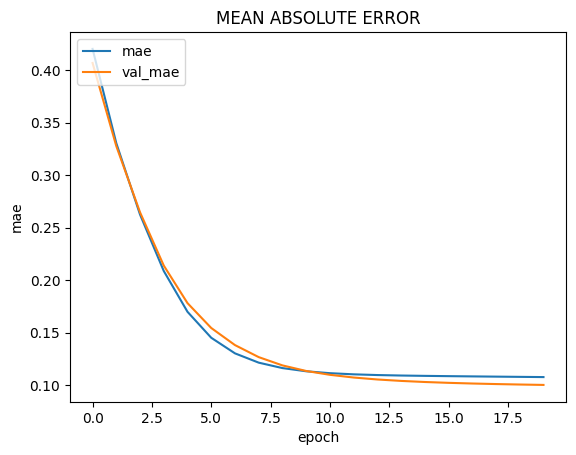

In [ ]:
# @markdown Post-Processing :\
# @markdown Mean Absolute Error Visualization Result

plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('MEAN ABSOLUTE ERROR')
plt.ylabel('mae')
plt.xlabel('epoch')
plt.legend(['mae', 'val_mae'], loc='upper left')
plt.show()

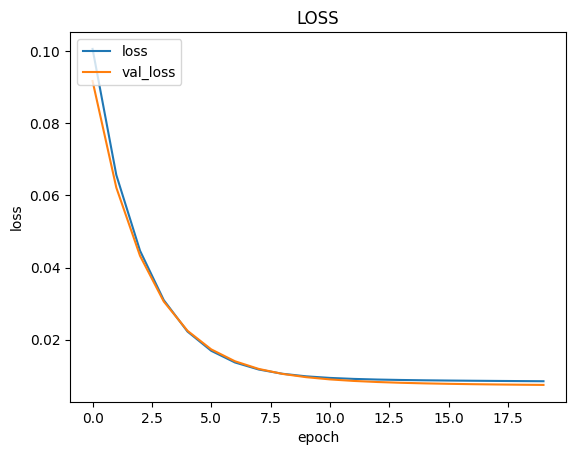

In [ ]:
# @markdown Post-Processing :\
# @markdown Loss Visualization Result

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('LOSS')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()

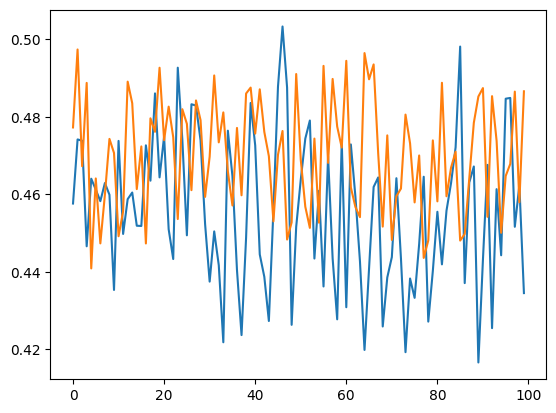

In [ ]:
# labelPredict = model.predict(windowedTestData)
# LabelTrain = model.predict(windowedTrainData)
plt.plot(labelPredict[:100])
plt.plot(LabelTrain[:100])